# 01 · Data Exploration

What is in the MAGFiLO Kaggle data, and what does it imply for cleaning, augmentation,
the validation split, the loss and the post-processing?

1. Inventory: observations, annotation sets, sites, dates, train vs test
2. Multiple annotation sets per observation
3. Image appearance: solar disk geometry, intensity, limb darkening, artefacts
4. Class imbalance
5. Filament morphology: size, thinness, spacing (matters for Panoptic Quality)
6. Annotation quality
7. Inter-annotator agreement (a human ceiling for PQ)
8. Temporal structure (matters for the split)

In [1]:
# --- Setup: works both locally and on Kaggle ---
import os, sys
from pathlib import Path

IN_KAGGLE = os.path.exists("/kaggle/input")

if IN_KAGGLE:
    # Pull the shared src/ code from GitHub (requires Internet ON in notebook settings)
    if not Path("/kaggle/working/COS711-A2").exists():
        !git clone -q https://github.com/AryanMohanlall/COS711-A2.git /kaggle/working/COS711-A2
    ROOT = Path("/kaggle/working/COS711-A2")
elif Path.cwd().name == "notebooks":
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()

sys.path.insert(0, str(ROOT))

from src.data import get_data_dir
DATA_DIR = get_data_dir()
print("Kaggle:", IN_KAGGLE, "| data dir:", DATA_DIR)

Kaggle: False | data dir: /home/aryan/Documents/COS711/COS711-A2/data/MAGFiLO_1.0_Kaggle_2026


In [2]:
import itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from src.data import SITES, load_annotations, list_test_images, load_image, instance_mask, instance_mask_for
from src.preprocess import find_disk
from src.metrics import panoptic_quality, match_instances

FIG_DIR = ROOT / "figures" / "01"
ART_DIR = ROOT / "artifacts"
FIG_DIR.mkdir(parents=True, exist_ok=True)
ART_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
SITE_ORDER = list(SITES)

images, anns = load_annotations(DATA_DIR)
test = list_test_images(DATA_DIR)

# One row per train observation (an observation can have several annotation sets)
train_obs = images.drop_duplicates("obs")
train_obs = train_obs[["obs", "time", "site", "file_name", "path"]].reset_index(drop=True)

## 1. Inventory

In [3]:
print("Train observations (image files):", len(train_obs))
print("Train annotation sets (JSON image entries):", len(images))
print("Filament instances:", len(anns))
print("Test observations:", len(test))
print("Image sizes in JSON:", images[["height", "width"]].value_counts().to_dict())
h, w = load_image(test.path[0]).shape
print("Test image size (first file):", (h, w))

Train observations (image files): 707
Train annotation sets (JSON image entries): 1154
Filament instances: 8199
Test observations: 180
Image sizes in JSON: {(2048, 2048): 1154}
Test image size (first file): (2048, 2048)


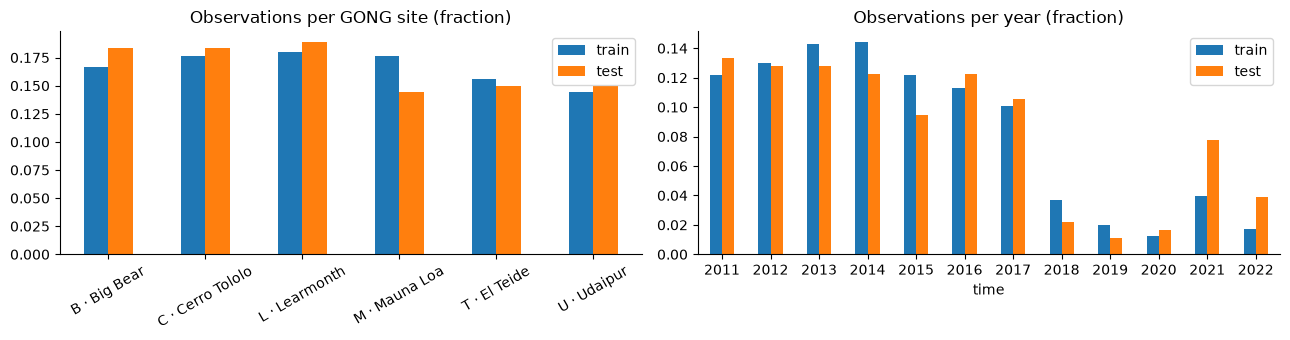

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))

site_counts = pd.DataFrame({
    "train": train_obs.site.value_counts(normalize=True),
    "test": test.site.value_counts(normalize=True),
})
site_counts = site_counts.loc[SITE_ORDER]
site_counts.index = [f"{s} · {SITES[s]}" for s in site_counts.index]
site_counts.plot.bar(ax=axes[0], rot=30, title="Observations per GONG site (fraction)")

year_counts = pd.DataFrame({
    "train": train_obs.time.dt.year.value_counts(normalize=True),
    "test": test.time.dt.year.value_counts(normalize=True),
})
year_counts = year_counts.sort_index()
year_counts.plot.bar(ax=axes[1], rot=0, title="Observations per year (fraction)")

plt.tight_layout()
savefig("inventory")
plt.show()

## 2. Annotation sets per observation

JSON image ids look like `<set_id>-<observation>`. How many sets does each observation have,
and what is the `set_id`?

In [5]:
sets_per_obs = images.groupby("obs").size()
print("Annotation sets per observation:", sets_per_obs.value_counts().sort_index().to_dict())
print("Distinct set_ids:", images.set_id.nunique())

# Do the sets of one observation share a set_id prefix?
multi_obs = sets_per_obs[sets_per_obs > 1].index
multi = images[images.obs.isin(multi_obs)]


def same_prefix(set_ids):
    return set_ids.str[:4].nunique() == 1


same = multi.groupby("obs").set_id.apply(same_prefix)
print("Same first-4-digit prefix within an observation:", same.mean())


def site_letters(sites):
    return "".join(sorted(set(sites)))


by_set = images.groupby("set_id")
set_summary = pd.DataFrame({
    "n": by_set.obs.size(),
    "sites": by_set.site.apply(site_letters),
    "first": by_set.time.min(),
    "last": by_set.time.max(),
})
set_summary.head(12)

Annotation sets per observation: {1: 411, 2: 145, 3: 151}
Distinct set_ids: 37
Same first-4-digit prefix within an observation: 1.0


,n,sites,first,last
set_id,,,,
010101,72,BCLMTU,2011-01-14 10:50:34,2021-10-16 14:50:50
010102,65,BCLMTU,2011-02-03 08:26:34,2020-01-10 07:32:30
010103,29,BCLMTU,2011-01-14 10:50:34,2021-02-22 22:28:50
010201,20,BCLMTU,2011-07-24 16:46:14,2021-12-25 02:58:50
010202,37,BCLMTU,2011-08-23 12:03:34,2022-06-17 18:53:52
010203,37,BCLMTU,2011-08-23 12:03:34,2022-07-10 08:51:52
010301,10,BCLMT,2011-02-13 09:34:14,2019-06-09 12:33:30
010302,16,BCLMTU,2011-02-13 09:34:14,2021-06-24 13:39:50
010303,5,BCU,2016-02-04 13:37:34,2021-06-24 13:39:50


### Examples: one observation per site (first annotation set outlined)

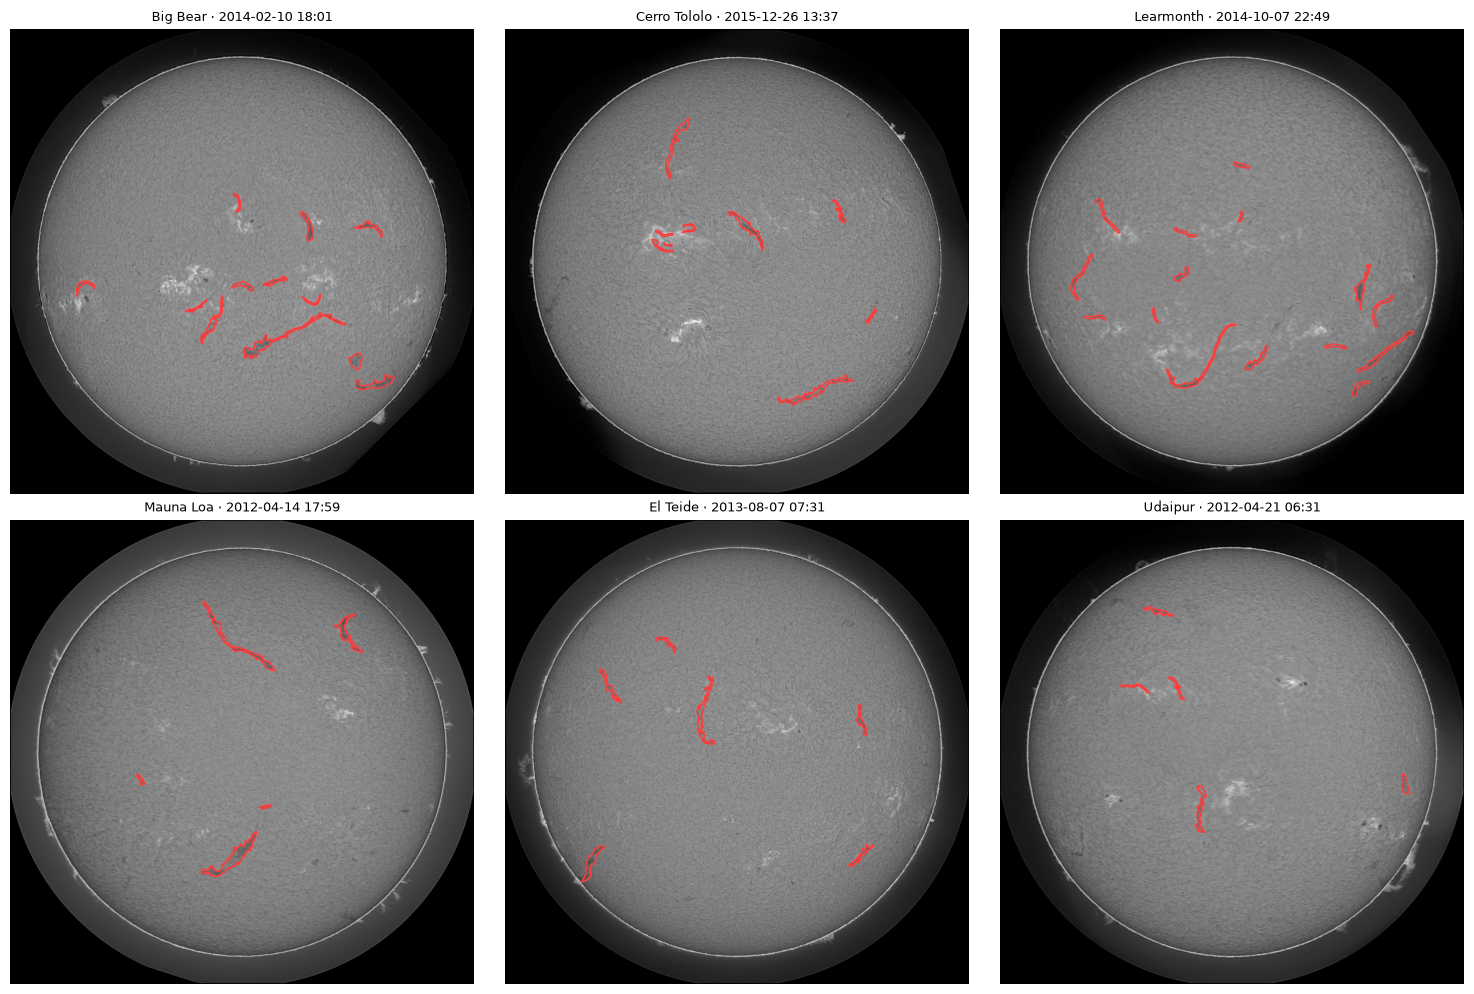

In [6]:
def show_with_mask(ax, path, image_id, size=1024, title=None):
    img = load_image(path)
    mask = instance_mask_for(image_id, anns, img.shape)
    scale = size / img.shape[0]
    img_small = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(img_small, cv2.COLOR_GRAY2RGB)

    # Outline every filament in red
    for k in np.unique(mask)[1:]:
        contours, _ = cv2.findContours((mask == k).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        scaled = []
        for c in contours:
            scaled.append(np.round(c * scale).astype(np.int32))
        cv2.drawContours(rgb, scaled, -1, (255, 60, 60), 2)

    ax.imshow(rgb)
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=9)


first_set = images.drop_duplicates("obs")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i in range(len(SITE_ORDER)):
    site = SITE_ORDER[i]
    r = first_set[first_set.site == site].sample(1, random_state=0).iloc[0]
    title = SITES[site] + " · " + r.time.strftime("%Y-%m-%d %H:%M")
    show_with_mask(axes.flat[i], r.path, r.image_id, title=title)
plt.tight_layout()
savefig("examples_per_site")
plt.show()

## 3. Image appearance

Per image (train **and** test, test pixels only, no labels): locate the solar disk with
`src.preprocess.find_disk` (circle fit to the limb; global Otsu thresholding was tried first but
fails on images with a bright off-limb halo, overestimating the radius by up to 125 px), then measure disk centre/radius, intensity inside the disk,
saturation, and the radial intensity profile (limb darkening).

In [7]:
SMALL = 512                       # statistics are computed on a 512 px copy of each image
BINS = np.linspace(0, 1.2, 49)    # radial bins in units of the disk radius


def image_stats(path):
    img = load_image(path)
    H = img.shape[0]
    cx, cy, R = find_disk(img)
    small = cv2.resize(img, (SMALL, SMALL), interpolation=cv2.INTER_AREA)
    cx_s = cx * SMALL / H
    cy_s = cy * SMALL / H
    r_s = R * SMALL / H

    # Distance of every pixel from the disk centre, in units of the radius
    yy, xx = np.mgrid[:SMALL, :SMALL]
    rr = np.hypot(xx - cx_s, yy - cy_s) / r_s
    disk = rr < 0.98
    vals = small[disk].astype(np.float32)

    # Mean intensity per radial bin (the limb-darkening profile)
    idx = np.digitize(rr, BINS).ravel() - 1
    sums = np.bincount(idx, weights=small.ravel(), minlength=len(BINS))[: len(BINS) - 1]
    cnts = np.bincount(idx, minlength=len(BINS))[: len(BINS) - 1]

    return {
        "cx": cx, "cy": cy, "radius": R,
        "disk_mean": vals.mean(), "disk_std": vals.std(),
        "disk_p1": np.percentile(vals, 1), "disk_p99": np.percentile(vals, 99),
        "sat_frac": (img >= 250).mean(),
        "off_disk_mean": small[rr > 1.05].mean(),
        "profile": sums / np.maximum(cnts, 1),
    }


train_part = train_obs.copy()
train_part["split"] = "train"
test_part = test.copy()
test_part["split"] = "test"
all_obs = pd.concat([train_part, test_part], ignore_index=True)

stat_rows = []
for path in tqdm(all_obs.path):
    stat_rows.append(image_stats(path))
stats = pd.DataFrame(stat_rows)
stats = pd.concat([all_obs[["obs", "time", "site", "split"]], stats], axis=1)
stats.drop(columns="profile").to_csv(ART_DIR / "image_stats.csv", index=False)

summary_cols = ["radius", "cx", "cy", "disk_mean", "disk_std", "sat_frac", "off_disk_mean"]
stats.drop(columns="profile").groupby(["site", "split"])[summary_cols].mean()

  0%|          | 0/887 [00:00<?, ?it/s]

radius        cx        cy  disk_mean  disk_std   sat_frac  \
site split                                                                
B    test   907.218  1021.600  1022.762    127.676    14.265  2.276e-06   
     train  906.616  1021.140  1022.532    127.102    14.494  4.542e-06   
C    test   905.033  1022.438  1022.881    126.133    15.344  7.694e-06   
     train  904.985  1022.337  1022.976    126.864    15.359  6.048e-06   
L    test   905.029  1022.106  1022.228    125.596    15.791  1.010e-05   
     train  905.196  1022.075  1022.105    125.165    15.667  8.318e-06   
M    test   905.429  1021.005  1022.579    125.705    15.382  4.823e-06   
     train  905.483  1021.152  1022.619    125.948    15.117  3.284e-06   
T    test   907.850  1021.059  1022.943    123.094    16.270  1.466e-06   
     train  907.554  1020.885  1022.907    123.243    16.022  6.517e-06   
U    test   906.467  1021.551  1022.795    126.028    15.359  9.334e-06   
     train  906.151  1021.326  1022.939    126.385    15.194  4.507e-06   

            off_disk_mean  
site split                 
B    test          14.708  
     train         14.538  
C    test          10.237  
     train          9.650  
L    test           9.101  
     train          8.533  
M    test          11.296  
     train          8.872  
T    test          19.352  
     train         18.361  
U    test          12.577  
     train         11.258

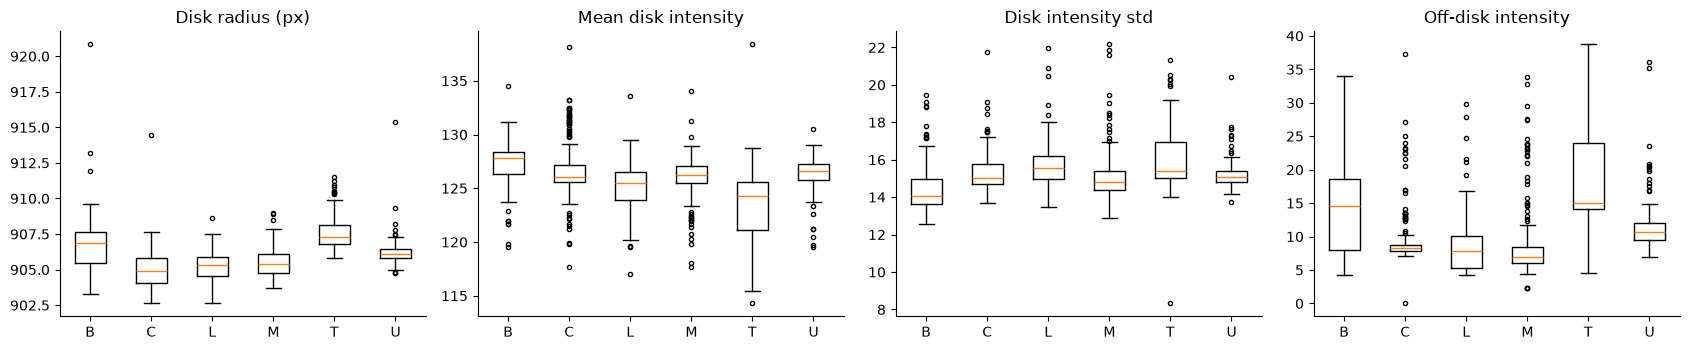

Disk centre offset from image centre: median 2.9 px, max 15.6 px
Disk radius: 906.0 ± 1.6 px (min 903, max 921)


In [8]:
columns = ["radius", "disk_mean", "disk_std", "off_disk_mean"]
titles = ["Disk radius (px)", "Mean disk intensity", "Disk intensity std", "Off-disk intensity"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for i in range(len(columns)):
    data = []
    for s in SITE_ORDER:
        data.append(stats.loc[stats.site == s, columns[i]])
    axes[i].boxplot(data, tick_labels=SITE_ORDER, showfliers=True, flierprops={"markersize": 3})
    axes[i].set_title(titles[i])
plt.tight_layout()
savefig("appearance_per_site")
plt.show()

offset = np.hypot(stats.cx - 1024, stats.cy - 1024)
print(f"Disk centre offset from image centre: median {round(offset.median(), 1)} px, max {round(offset.max(), 1)} px")
r_mean = round(stats.radius.mean(), 1)
r_std = round(stats.radius.std(), 1)
r_min = int(round(stats.radius.min()))
r_max = int(round(stats.radius.max()))
print(f"Disk radius: {r_mean} ± {r_std} px (min {r_min}, max {r_max})")

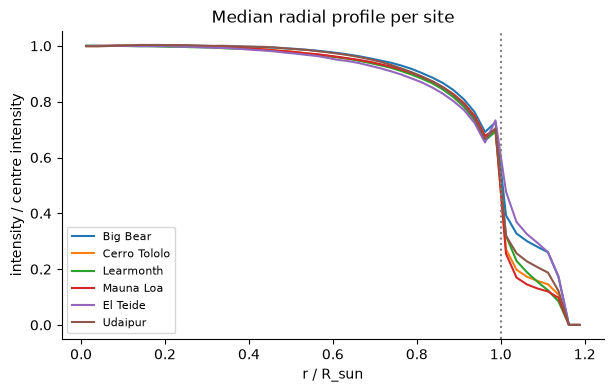

In [9]:
# Radial profile = limb darkening. Normalised by the centre intensity so sites are comparable.
centers = 0.5 * (BINS[1:] + BINS[:-1])
fig, ax = plt.subplots(figsize=(7, 4))
for s in SITE_ORDER:
    P = np.stack(stats.loc[stats.site == s, "profile"])
    P = P / P[:, :5].mean(axis=1, keepdims=True)
    ax.plot(centers, np.median(P, axis=0), label=SITES[s])
ax.axvline(1, color="grey", ls=":")
ax.set(xlabel="r / R_sun", ylabel="intensity / centre intensity", title="Median radial profile per site")
ax.legend(fontsize=8)
savefig("radial_profile")
plt.show()

### Outliers

Images whose statistics are far from their site's typical values could be clouds, bad seeing or
failed disk detection. Robust z-scores per site. The saturated fraction is left out: it is ~0 for
almost every image, so its MAD is ~0 and it flags ordinary bright plage/flare regions.

Images with |z| > 5: 100 {'test': 26, 'train': 74}
{'off_disk_mean': 60, 'disk_p1': 20, 'disk_mean': 11, 'disk_std': 9}
Max saturated fraction: 0.000628 (negligible)


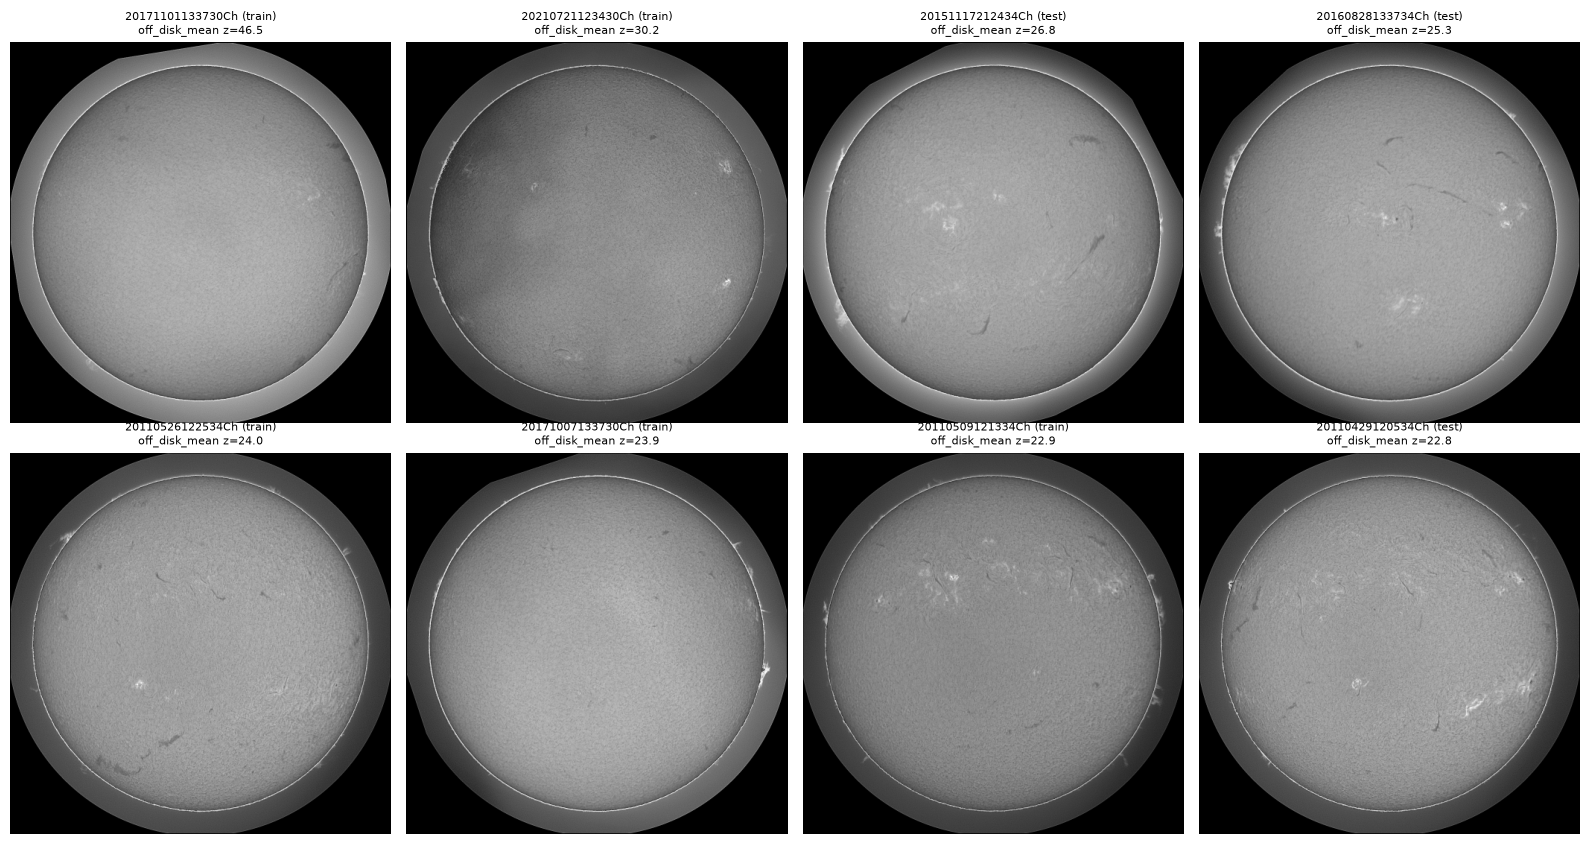

In [10]:
def robust_z(x):
    # Like a z-score, but with median and MAD so a few extreme images do not hide each other
    med = x.median()
    mad = (x - med).abs().median() * 1.4826
    return (x - med) / max(mad, 1e-3 * abs(med) + 1e-6)


cols = ["disk_mean", "disk_std", "disk_p1", "off_disk_mean"]
z = stats.groupby("site")[cols].transform(robust_z)
stats["outlier_score"] = z.abs().max(axis=1)
stats["outlier_reason"] = z.abs().idxmax(axis=1)

outliers = stats[stats.outlier_score > 5]
print("Images with |z| > 5:", len(outliers), outliers.groupby("split").size().to_dict())
print(outliers.outlier_reason.value_counts().to_dict())
print(f"Max saturated fraction: {round(stats.sat_frac.max(), 6)} (negligible)")

worst = stats.sort_values("outlier_score", ascending=False).head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for i in range(len(worst)):
    r = worst.iloc[i]
    ax = axes.flat[i]
    p = all_obs.loc[all_obs.obs == r.obs, "path"].iloc[0]
    ax.imshow(cv2.resize(load_image(p), (512, 512), interpolation=cv2.INTER_AREA), cmap="gray")
    ax.set_title(f"{r.obs} ({r.split})\n{r.outlier_reason} z={round(r.outlier_score, 1)}", fontsize=8)
    ax.set_axis_off()
plt.tight_layout()
savefig("outliers")
plt.show()
stats.drop(columns="profile").to_csv(ART_DIR / "image_stats.csv", index=False)

## 4–5. Class imbalance and filament morphology

Rasterise every annotation set at full resolution and measure each filament:
area, spine length, mean width (area / spine length), position on the disk, overlap with
other filaments, and the gap to its nearest neighbour (small gaps → risk of merging).

In [11]:
disk_geom = stats.set_index("obs")[["cx", "cy", "radius"]]
H = W = 2048
MARGIN = 40   # padding (px) around each filament's bounding box, for the gap to its neighbours


def measure_set(image_id, group):
    """Measure every filament of one annotation set. Returns (one row per filament, a summary of the set)."""
    obs = group.obs.iloc[0]
    cx, cy, R = disk_geom.loc[obs]
    count = np.zeros((H, W), np.uint8)   # how many filaments cover each pixel
    boxes = []
    crops = []
    rows = []

    for i in range(len(group)):
        ann = group.iloc[i]
        p = np.round(ann.polygon).astype(np.int32)
        spine = ann.spine

        # Rasterise the polygon inside its padded bounding box
        low = np.clip(p.min(0) - MARGIN, 0, W - 1)
        high = np.clip(p.max(0) + 1 + MARGIN, 1, W)
        x0, y0 = low[0], low[1]
        x1, y1 = high[0], high[1]
        crop = np.zeros((y1 - y0, x1 - x0), np.uint8)
        cv2.fillPoly(crop, [p - [x0, y0]], 1)
        count[y0:y1, x0:x1] += crop
        boxes.append((x0, y0, x1, y1))
        crops.append(crop)

        area = int(crop.sum())
        ys, xs = np.nonzero(crop)

        if len(spine) > 1:
            spine_len = float(np.linalg.norm(np.diff(spine, axis=0), axis=1).sum())
        else:
            spine_len = 0.0

        n_labels, _ = cv2.connectedComponents(crop)
        n_components = n_labels - 1   # label 0 is the background

        if area:
            mx = xs.mean() + x0
            my = ys.mean() + y0
        else:
            mx = np.nan
            my = np.nan

        if spine_len > 0:
            width = area / spine_len
        else:
            width = np.nan

        rows.append({"ann_id": ann.id, "image_id": image_id, "obs": obs, "category": ann.category,
                     "area_px": area, "n_vertices": len(p), "n_components": n_components,
                     "spine_len": spine_len, "width": width,
                     "r_over_R": np.hypot(mx - cx, my - cy) / R})

    # Overlap and nearest-neighbour gap, computed in each filament's padded box
    for i in range(len(boxes)):
        x0, y0, x1, y1 = boxes[i]
        crop = crops[i]
        box_count = count[y0:y1, x0:x1]
        others = (box_count - crop) > 0
        dist = cv2.distanceTransform((crop == 0).astype(np.uint8), cv2.DIST_L2, 5)
        if others.any():
            rows[i]["nn_gap"] = float(dist[others].min())
        else:
            rows[i]["nn_gap"] = np.inf
        rows[i]["overlap_px"] = int((box_count[crop > 0] > 1).sum())

    fg = count > 0
    disk_area = np.pi * R ** 2
    summary = {"image_id": image_id, "obs": obs, "n_instances": len(group),
               "fg_frac_image": fg.mean(), "fg_frac_disk": fg.sum() / disk_area,
               "overlap_px": int((count > 1).sum())}
    return rows, summary


inst_rows = []
set_rows = []
for image_id, g in tqdm(anns.groupby("image_id")):
    rows, summary = measure_set(image_id, g)
    inst_rows.extend(rows)
    set_rows.append(summary)
inst = pd.DataFrame(inst_rows)
sets = pd.DataFrame(set_rows).merge(images[["image_id", "site", "set_id"]], on="image_id")
inst.to_csv(ART_DIR / "instance_stats.csv", index=False)
sets.to_csv(ART_DIR / "annotation_set_stats.csv", index=False)

  0%|          | 0/1154 [00:00<?, ?it/s]

### Class imbalance

Filament pixels as % of image: mean 0.39%, median 0.33%, max 1.73%
Filament pixels as % of solar disk: mean 0.63%
Background:filament pixel ratio ≈ 258:1


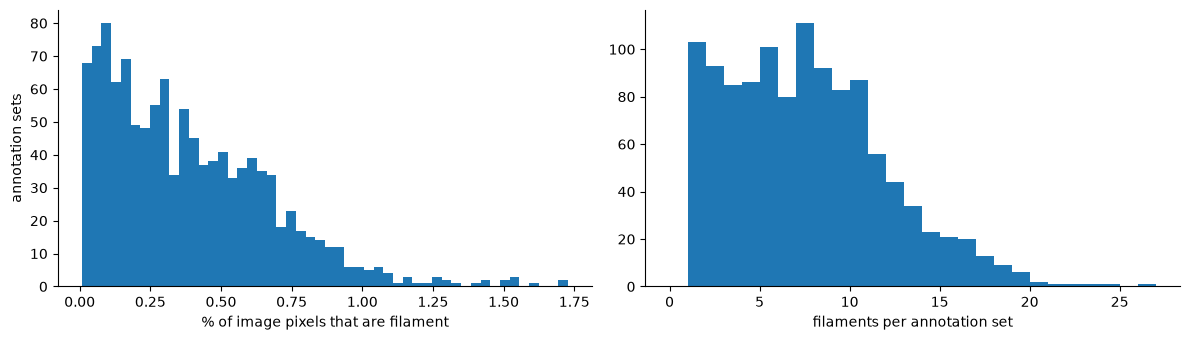

In [12]:
mean_pct = round(100 * sets.fg_frac_image.mean(), 2)
median_pct = round(100 * sets.fg_frac_image.median(), 2)
max_pct = round(100 * sets.fg_frac_image.max(), 2)
print(f"Filament pixels as % of image: mean {mean_pct}%, median {median_pct}%, max {max_pct}%")
print(f"Filament pixels as % of solar disk: mean {round(100 * sets.fg_frac_disk.mean(), 2)}%")
print(f"Background:filament pixel ratio ≈ {int(round(1 / sets.fg_frac_image.mean()))}:1")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(100 * sets.fg_frac_image, bins=50)
axes[0].set(xlabel="% of image pixels that are filament", ylabel="annotation sets")
axes[1].hist(sets.n_instances, bins=range(0, sets.n_instances.max() + 2))
axes[1].set(xlabel="filaments per annotation set")
plt.tight_layout()
savefig("class_imbalance")
plt.show()

### Morphology

In [13]:
morph_cols = ["area_px", "spine_len", "width", "n_vertices", "r_over_R", "nn_gap"]
morph = inst.replace([np.inf], np.nan)[morph_cols]
morph.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
area_px,8199.0,2293.131,2858.743,18.000,252.940,369.000,757.500,1365.000,2646.000,7340.800,14405.680,39060.000
spine_len,8199.0,147.431,118.884,12.069,28.971,40.675,70.554,111.268,182.493,386.901,627.520,1104.954
width,8199.0,13.930,6.865,0.105,5.456,6.654,9.408,12.272,16.388,26.842,38.944,72.058
n_vertices,8199.0,79.069,65.161,6.000,14.000,19.000,36.000,60.000,100.000,201.100,326.020,707.000
r_over_R,8199.0,0.565,0.199,0.013,0.105,0.215,0.419,0.582,0.727,0.853,0.901,0.962
nn_gap,1762.0,43.543,38.263,0.000,0.610,4.197,18.636,34.757,54.339,119.497,193.986,270.721


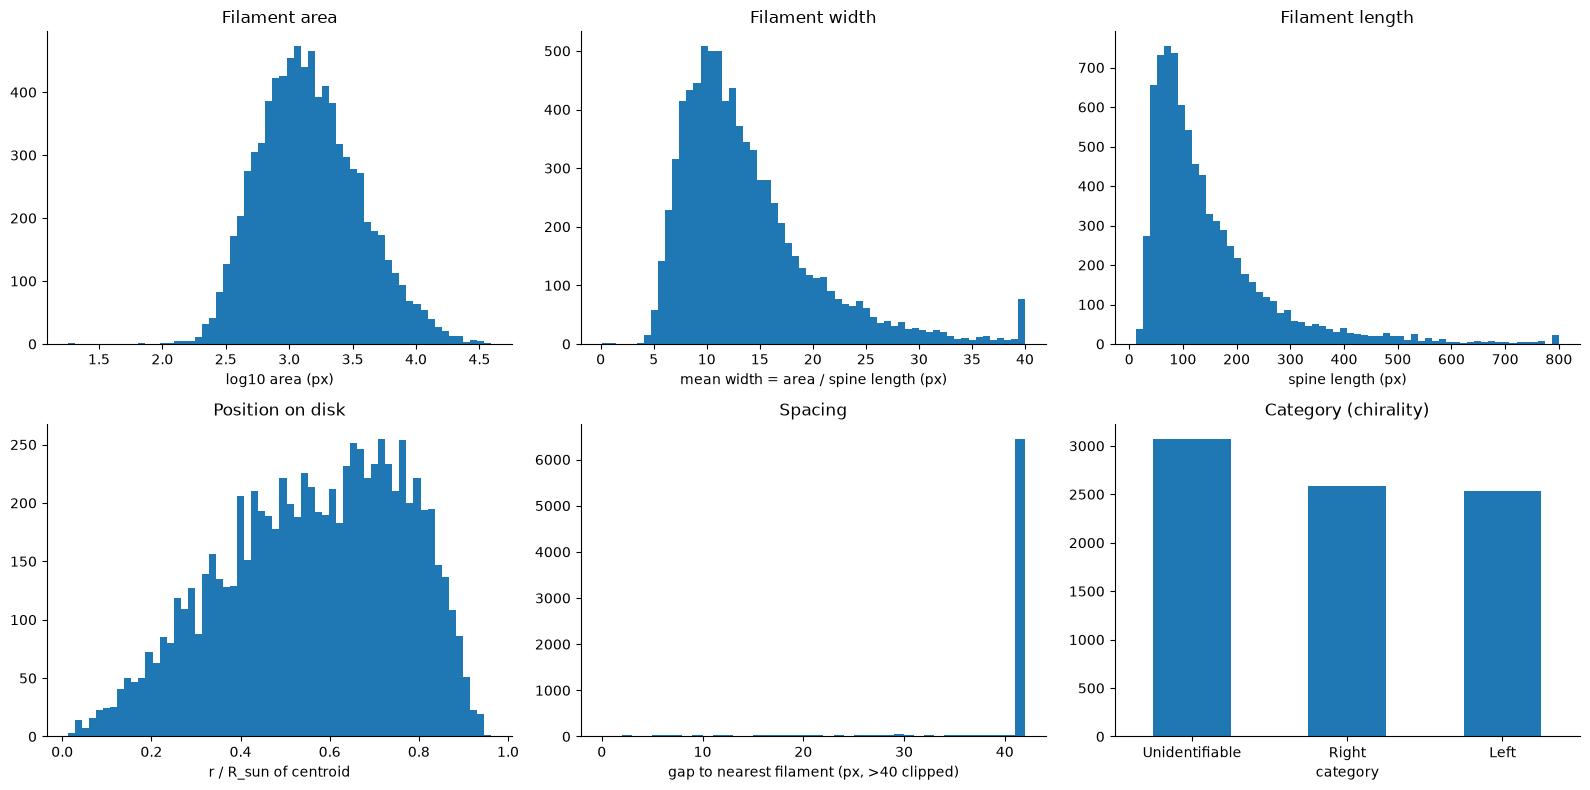

Filaments with a neighbour within 1 px: 0.3%
Filaments with a neighbour within 3 px: 0.9%
Filaments with a neighbour within 5 px: 1.4%
Filaments with a neighbour within 10 px: 2.9%
Filaments with a neighbour within 20 px: 5.8%
Filaments narrower than 4px mean width: 0.0%
Annotation sets with overlapping polygons: 9 / 1154


In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes[0, 0].hist(np.log10(inst.area_px.clip(lower=1)), bins=60)
axes[0, 0].set(xlabel="log10 area (px)", title="Filament area")

axes[0, 1].hist(inst.width.dropna().clip(upper=40), bins=60)
axes[0, 1].set(xlabel="mean width = area / spine length (px)", title="Filament width")

axes[0, 2].hist(inst.spine_len.clip(upper=800), bins=60)
axes[0, 2].set(xlabel="spine length (px)", title="Filament length")

axes[1, 0].hist(inst.r_over_R.clip(upper=1.2), bins=60)
axes[1, 0].set(xlabel="r / R_sun of centroid", title="Position on disk")

gap = inst.nn_gap.replace(np.inf, MARGIN + 1)   # no neighbour inside the box: show as > MARGIN
axes[1, 1].hist(gap, bins=np.arange(0, MARGIN + 3))
axes[1, 1].set(xlabel=f"gap to nearest filament (px, >{MARGIN} clipped)", title="Spacing")

inst.category.value_counts().plot.bar(ax=axes[1, 2], rot=0, title="Category (chirality)")
plt.tight_layout()
savefig("morphology")
plt.show()

for t in [1, 3, 5, 10, 20]:
    share = 100 * (inst.nn_gap <= t).mean()
    print(f"Filaments with a neighbour within {t} px: {round(share, 1)}%")
print(f"Filaments narrower than 4px mean width: {round(100 * (inst.width < 4).mean(), 1)}%")
print("Annotation sets with overlapping polygons:", (sets.overlap_px > 0).sum(), "/", len(sets))

## 6. Annotation quality checks

Degenerate polygons, polygons that rasterise into several pieces, filaments off the disk,
overlaps, and spines that leave their polygon.

In [15]:
inst["off_disk"] = inst.r_over_R > 1.0
checks = {
    "area < 20 px": (inst.area_px < 20).sum(),
    "< 4 vertices": (inst.n_vertices < 4).sum(),
    "rasterises into >1 component": (inst.n_components > 1).sum(),
    "centroid off the disk": inst.off_disk.sum(),
    "overlaps another filament": (inst.overlap_px > 0).sum(),
    "no spine": (inst.spine_len == 0).sum(),
}
pd.Series(checks, name="instances").to_frame()

,instances
area < 20 px,1
< 4 vertices,0
rasterises into >1 component,0
centroid off the disk,0
overlaps another filament,18
no spine,0


In [16]:
# Fraction of spine points inside their own polygon (spines are presumably drawn inside the filament)
def spine_inside(poly, spine):
    if len(spine) == 0:
        return np.nan
    contour = poly.reshape(-1, 1, 2)
    inside = []
    for x, y in spine:
        inside.append(cv2.pointPolygonTest(contour, (float(x), float(y)), False) >= 0)
    return np.mean(inside)


fractions = []
for i in range(len(anns)):
    fractions.append(spine_inside(anns.polygon.iloc[i], anns.spine.iloc[i]))
anns["spine_inside"] = fractions
print(f"Mean fraction of spine points inside polygon: {round(anns.spine_inside.mean(), 3)}")
print("Instances with < 50% of spine inside:", (anns.spine_inside < 0.5).sum())

Mean fraction of spine points inside polygon: 0.952
Instances with < 50% of spine inside: 26


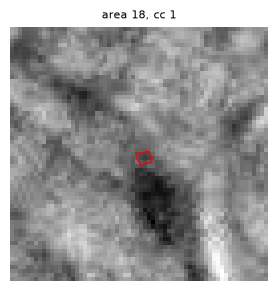

In [17]:
# Show the most suspicious instances
suspicious = (inst.n_components > 1) | (inst.area_px < 20) | inst.off_disk
sus = inst[suspicious].head(8)
if len(sus):
    fig, axes = plt.subplots(1, len(sus), figsize=(3 * len(sus), 3))
    axes = np.atleast_1d(axes)   # one subplot is returned as a single Axes, not an array
    for i in range(len(sus)):
        r = sus.iloc[i]
        a = anns.loc[anns.id == r.ann_id].iloc[0]
        img = load_image(images.loc[images.image_id == r.image_id, "path"].iloc[0])
        low = np.maximum(a.polygon.min(0).astype(int) - 30, 0)
        high = a.polygon.max(0).astype(int) + 30
        x0, y0 = low[0], low[1]
        x1, y1 = high[0], high[1]
        closed = np.vstack([a.polygon, a.polygon[:1]]) - [x0, y0]   # repeat the first point to close the outline
        axes[i].imshow(img[y0:y1, x0:x1], cmap="gray")
        axes[i].plot(closed[:, 0], closed[:, 1], "r-", lw=1)
        axes[i].set_title(f"area {r.area_px}, cc {r.n_components}", fontsize=8)
        axes[i].set_axis_off()
    plt.tight_layout()
    savefig("suspicious_instances")
    plt.show()

## 7. Inter-annotator agreement

For observations with several annotation sets, score each set against the others with the
competition metric. This is roughly the best PQ a model can hope for, and tells us how noisy
the labels are.

In [18]:
multi_images = images[images.obs.isin(multi_obs)]
agree = []
for obs, g in tqdm(multi_images.groupby("obs")):
    masks = {}
    for iid in g.image_id:
        masks[iid] = instance_mask_for(iid, anns)
    # every pair of annotation sets of this observation
    for a, b in itertools.combinations(masks, 2):
        pq = panoptic_quality(masks[a], masks[b])
        fa = masks[a] > 0
        fb = masks[b] > 0
        row = {"obs": obs, "site": g.site.iloc[0], "set_a": a, "set_b": b}
        row.update(pq)
        row["pixel_iou"] = (fa & fb).sum() / max((fa | fb).sum(), 1)
        row["n_a"] = int(masks[a].max())
        row["n_b"] = int(masks[b].max())
        agree.append(row)
agree = pd.DataFrame(agree)
agree.to_csv(ART_DIR / "inter_annotator.csv", index=False)
print("Pairs:", len(agree), " |  identical pairs (PQ == 1):", (agree.pq > 0.999).sum())
agree[["pq", "sq", "rq", "pixel_iou"]].describe()

  0%|          | 0/296 [00:00<?, ?it/s]

Pairs: 598  |  identical pairs (PQ == 1): 0


,pq,sq,rq,pixel_iou
count,598.000,598.000,598.000,598.000
mean,0.361,0.612,0.561,0.467
std,0.166,0.143,0.246,0.136
min,0.000,0.000,0.000,0.000
25%,0.259,0.599,0.400,0.385
50%,0.363,0.637,0.571,0.485
75%,0.478,0.672,0.727,0.562
max,0.812,0.812,1.000,0.812


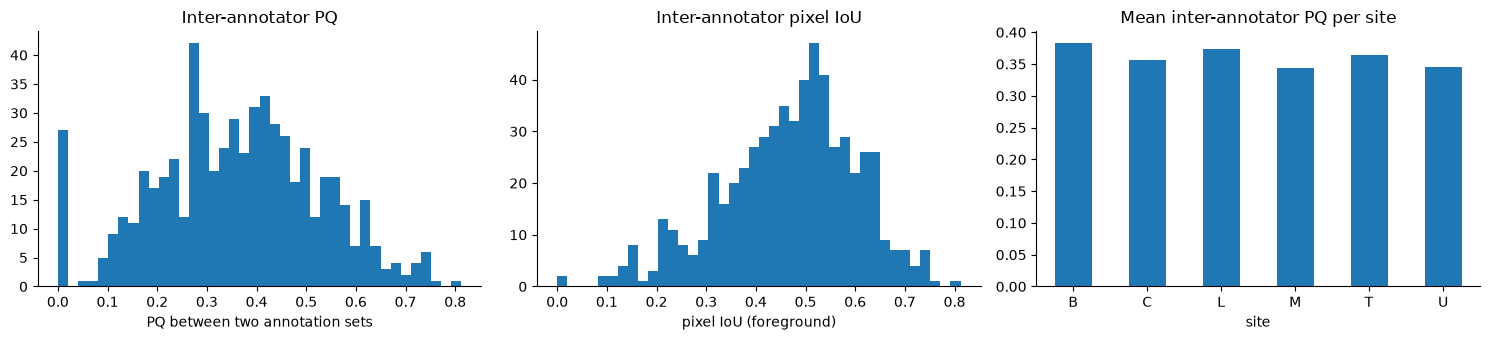

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(agree.pq, bins=40)
axes[0].set(xlabel="PQ between two annotation sets", title="Inter-annotator PQ")
axes[1].hist(agree.pixel_iou, bins=40)
axes[1].set(xlabel="pixel IoU (foreground)", title="Inter-annotator pixel IoU")
pq_per_site = agree.groupby("site").pq.mean().reindex(SITE_ORDER)
pq_per_site.plot.bar(ax=axes[2], rot=0, title="Mean inter-annotator PQ per site")
plt.tight_layout()
savefig("inter_annotator")
plt.show()

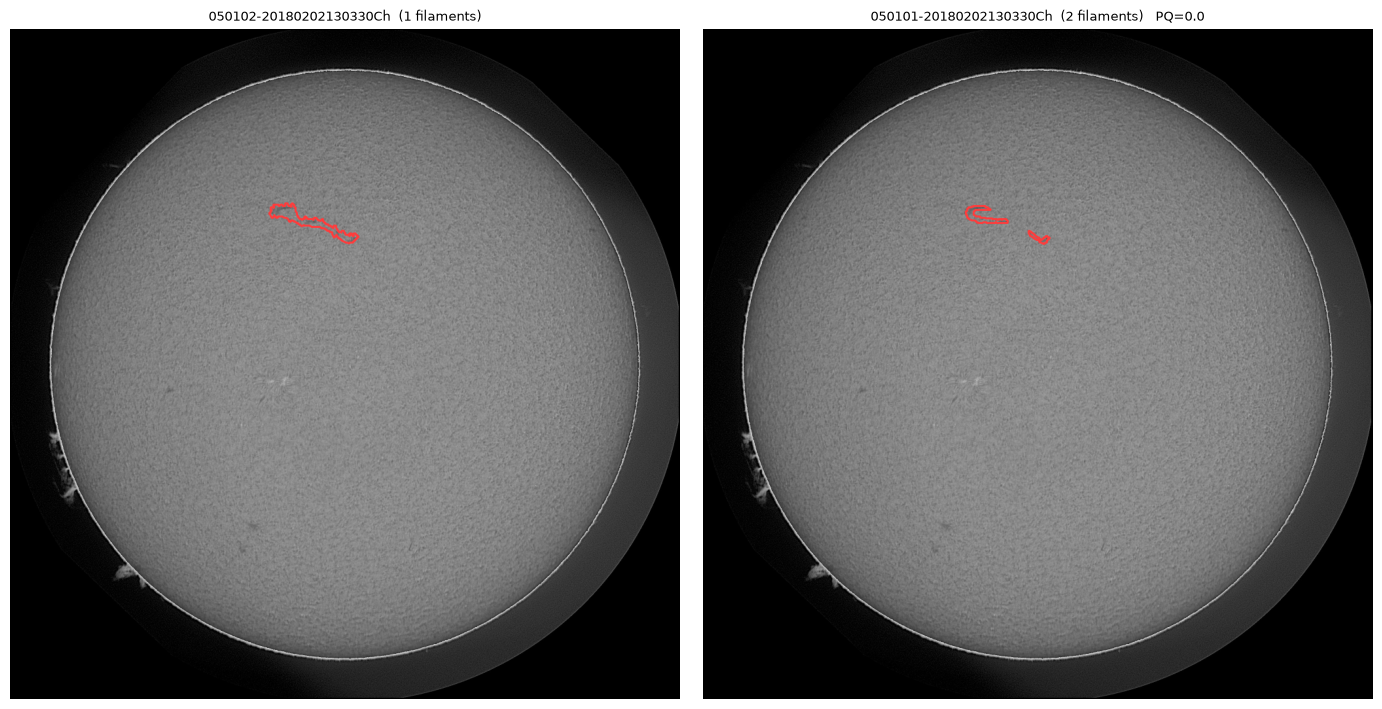

In [20]:
# Largest disagreement, side by side
r = agree.sort_values("pq").iloc[0]
p = images.loc[images.image_id == r.set_a, "path"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
show_with_mask(axes[0], p, r.set_a, title=f"{r.set_a}  ({r.n_a} filaments)")
show_with_mask(axes[1], p, r.set_b, title=f"{r.set_b}  ({r.n_b} filaments)   PQ={round(r.pq, 2)}")
plt.tight_layout()
savefig("worst_agreement")
plt.show()

### Why do annotators disagree?

For each pair of sets, classify every filament in set A against set B:
**matched** (IoU > 0.5), **boundary/split/merge** (overlaps something but IoU ≤ 0.5),
or **missed** (no overlap at all: the other annotator did not mark it).

In [21]:
def disagreement(ma, mb):
    """Classify every filament of set A against set B: matched (IoU > 0.5), partial overlap, or missed."""
    out = {"matched": 0, "partial": 0, "missed": 0}
    matched_a = set()
    for g, _, _ in match_instances(ma, mb)["matches"]:
        matched_a.add(g)
    for k in np.unique(ma)[1:]:
        if k in matched_a:
            out["matched"] += 1
        elif (mb[ma == k] > 0).any():
            out["partial"] += 1
        else:
            out["missed"] += 1
    return out


rows = []
for obs, g in tqdm(multi_images.groupby("obs")):
    masks = {}
    for iid in g.image_id:
        masks[iid] = instance_mask_for(iid, anns)
    # every ordered pair: A against B and B against A
    for a, b in itertools.permutations(masks, 2):
        rows.append(disagreement(masks[a], masks[b]))
dis = pd.DataFrame(rows).sum()
print((100 * dis / dis.sum()).round(1).to_string())

  0%|          | 0/296 [00:00<?, ?it/s]

matched    56.1
partial    26.2
missed     17.7


## 8. Temporal structure

How close in time are observations? Near-simultaneous observations from different sites show
the same filaments, so they are not independent and must sit on the same side of the split.

Train observations within 24h of the previous one: 16.8%
Train observations within 1h of the previous one: 1.3%
Train pairs < 1h apart from different sites: 9, e.g. [('20120330063134Lh', '20120330063154Uh'), ('20130303063134Lh', '20130303063154Uh'), ('20140615195814Mh', '20140615195854Bh')]
Test observations with a train observation within 24h: 35.0%
Test observations with a train observation within 7 days: 95.0%


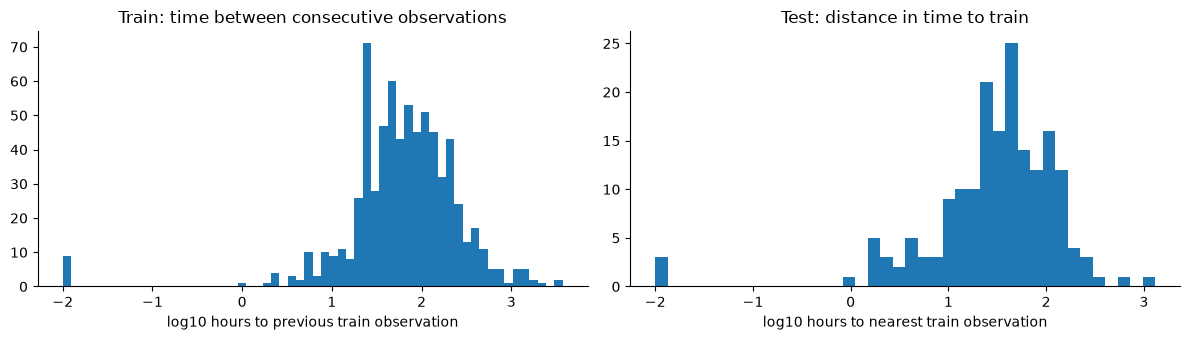

In [22]:
t = train_obs.sort_values("time").reset_index(drop=True)
gaps_h = t.time.diff().dt.total_seconds() / 3600
print(f"Train observations within 24h of the previous one: {round(100 * (gaps_h < 24).mean(), 1)}%")
print(f"Train observations within 1h of the previous one: {round(100 * (gaps_h < 1).mean(), 1)}%")

# Near-simultaneous observations from different sites = the same Sun seen twice
close = []
for i in range(len(t) - 1):
    a = t.iloc[i]
    b = t.iloc[i + 1]
    if (b.time - a.time) < pd.Timedelta(hours=1) and a.site != b.site:
        close.append((a.obs, b.obs))
print(f"Train pairs < 1h apart from different sites: {len(close)}, e.g. {close[:3]}")

# Hours from each test observation to the closest train observation
test_times = test.time.values[:, None]
train_times = train_obs.time.values[None, :]
nearest_train_h = np.abs(test_times - train_times).min(axis=1) / np.timedelta64(1, "h")
print(f"Test observations with a train observation within 24h: {round(100 * (nearest_train_h < 24).mean(), 1)}%")
print(f"Test observations with a train observation within 7 days: {round(100 * (nearest_train_h < 24 * 7).mean(), 1)}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.log10(gaps_h.dropna().clip(lower=0.01)), bins=60)
axes[0].set(xlabel="log10 hours to previous train observation", title="Train: time between consecutive observations")
axes[1].hist(np.log10(np.clip(nearest_train_h, 0.01, None)), bins=40)
axes[1].set(xlabel="log10 hours to nearest train observation", title="Test: distance in time to train")
plt.tight_layout()
savefig("temporal")
plt.show()

## Summary of findings → decisions

| # | Finding | Decision / implication |
|---|---------|------------------------|
| 1 | 707 train observations, **1154 annotation sets** (411 obs × 1, 145 × 2, 151 × 3), 8199 filaments; 180 test images. All 2048×2048 JPEG. Six GONG sites, roughly balanced; train and test match in site and year distribution (2011–2022). | No distribution shift to correct. Stratify the split by site. |
| 2 | **Disk geometry is already standardised**: radius 906 ± 1.6 px, centre within ~3 px of the image centre. Otsu thresholding fails on haloed images (radius off by up to 125 px), so a limb circle-fit is used (`src.preprocess.find_disk`). All filaments lie on the disk (max r/R 0.96). | Mask out everything off the disk. Rotation about the image centre is a valid augmentation; scale augmentation is not needed. |
| 3 | Disk brightness is already normalised by GONG (mean ≈ 125 at every site). Limb darkening to ≈ 0.7 at the limb, bright rim artefact at r ≈ 0.98. ~11% of images are degraded (bright off-limb halo, haze, illumination gradients, banding), mostly Cerro Tololo, **in both train and test**. Saturation is negligible. | Do **not** drop degraded images. Per-image normalisation inside the disk; compare with/without limb-darkening flattening. Augment brightness/contrast/gamma, smooth illumination gradients, blur. |
| 4 | **Severe class imbalance**: filaments are 0.39% of image pixels (≈ 258:1), 0.63% of the disk. 1–26 filaments per set (median 7). | Overlap-based losses (Dice/Tversky) or focal loss rather than plain BCE; if training on patches, oversample patches containing filaments. |
| 5 | Filaments are elongated: median length 111 px, median mean width 12 px (5th percentile 6.7 px). Only 2.9% have a neighbour within 10 px. | Input at 1024 keeps nearly all filaments ≥ 3 px wide; 512 would erase fine structure. Merging neighbours is rare but costly under PQ, so watch the close pairs. |
| 6 | Annotations are geometrically clean: 1 tiny polygon, none splitting into pieces, 18 overlapping instances (9 sets). Each filament also has a **spine** (centre line), 95% inside its polygon. | Minimal cleaning. Spines are a free auxiliary target for continuity (skeleton / distance-to-spine supervision). |
| 7 | **Labels are noisy and incomplete**: inter-annotator PQ 0.36 ± 0.17, pixel IoU 0.47. Of filaments marked by one annotator, 56% are matched by another, 26% disagree on extent/splitting, and **18% are not marked at all**. | The PQ achievable against a single annotator is limited. Compare: each set as a separate sample vs. consensus (union / majority vote). Avoid penalising "false positives" too harshly. Chirality categories are not needed for PQ. |
| 8 | 16.8% of train observations are within 24 h of another; 9 pairs < 1 h apart from different sites (same Sun). Test images are interleaved in time with train (95% within 7 days of a train image). | Split by observation **and** time window (group observations from the same day/few days), stratified by site. A year-based split is not needed, since test is interleaved. |
